In [1]:
RERUN = False
from _common import *
from _dna_helpers import *
import matplotlib.pyplot as plt

FIG4 = RESULTS / "dna" / "fig4"
have = lambda p: (FIG4 / p).exists()
print("results/dna/fig4:", sorted(x.name for x in FIG4.glob("*")) or "(empty -- runs pending)")

# What the submitted PDF plotted, read back out of its vector figures (results/dna/figure_digitized,
# digitize_paper_figures.py; affine residual ~2e-5 pt). Read-only inputs owned by the DNA-results notebooks.
old_right = load_csv("dna/figure_digitized/fig4_right_nfe_benchmark_digitized.csv")
old_left = load_csv("dna/figure_digitized/fig4_left_MC_value_digitized.csv")
old_rerun = load_csv("dna/benchmarks/recovered_2026-05-13/nfe_benchmark_agg.csv")

results/dna/fig4: ['PROVENANCE.md', 'panelA_per_condition.csv.gz', 'panelA_value_error.csv', 'panelA_value_error_c0_reward.csv', 'panelA_value_error_first8_conditions.csv', 'panelB_curves.csv', 'panelB_pilot.csv', 'panelB_runs.csv', 'paper_sentences.md', 'pilot_choice.json', 'summary.json']


# 06 · DNA steering benchmarks — Figure 4 (both panels)

Paper §3.3, "Posterior Recovery" (left) and "Steering" (right).

> **This notebook does not reproduce the submitted figure; it replaces it** (authors'
> decision 3, 2026-09-29).
>
> *What was submitted.* Both panels were made in May 2026 from the `split65k` models and
> the Keras-derived C0 guide `dinko/C0free_torch.pt`, all purged; both run directories
> survive empty. The values *plotted* are recoverable exactly by digitizing the vector
> PDFs (`results/dna/figure_digitized/`): the four baseline curves of the right panel
> equal, to 1e-6, a CSV **hard-coded** in `scripts/benchmark_yeast_split_dmfm_steering.py`
> (lines 28–48) whose producing code was never in the repository (its `mae_sem` is
> `0.000000` in every row although `n_repeats` is 3); the left panel's producer *was*
> recovered (`results/dna/original_scripts/benchmark_yeast_split_value_mc.py`, verbatim
> from `tullebulle/DNA-MFM@187fe7b`) and is ported here, but no log of the plotted run
> survives, so its `--n_conditions` and `--n_list` are assumptions, not evidence.
> A 2026-05-13 rerun of the dMFM half survives
> (`results/dna/benchmarks/recovered_2026-05-13/`) but is *not* the plotted run (the figure
> PDF predates the checkpoints it used) and gives 8–36 % higher errors.
>
> *What is here.* Both panels rerun on the current **parent-disjoint L = 50** models
> with **real** implementations of best-of-N, Feynman–Kac steering, beam search and MCTS
> (`src/dmfm/benchmarks/`). Models, guide and baselines all changed, so the new curves are
> not numerically comparable to the submitted ones; the submitted values are overlaid
> (dotted) only so the reader can see what changed.

Everything is rebuilt from `results/dna/fig4/` (`RERUN = False`). `RERUN = True` reruns a
small-n version on one GPU. Full-size run: `sbatch --array=0-2 scripts/dna/fig4_all.sbatch`
(identical work-stealing workers over every shard — calibration, pilot, panel A, sweep —
each shard one JSON whose name carries its $n$ and seed and whose settings are recorded
and checked, so a preempted or resubmitted job resumes and two runs with different
settings can never mix), then `bash scripts/dna/fig4_collect.sh`.
Provenance and job IDs: `results/dna/fig4/PROVENANCE.md`. CPU self-test of the
implementation (sampler equivalence, branching, NFE accounting):
`python scripts/dna/fig4_selftest.py`.

## What is measured, and how NFE is counted

Common to every method: the parent-disjoint base DFM (`checkpoints/dna/base/L50`), the
C0 guide (`checkpoints/dna/c0/guide`, trained on the same `a` parents as the generator),
a 96-step grid, target $y^\star = 0.30$, reward $r(x) = -(f_{\mathrm{cyc}}(x) - y^\star)^2$
(the code carries the extra $1/2\sigma^2$, $\sigma = 0.15$, which changes no ranking), the
same seeds, and the *same* terminal scoring: the guide applied to the hard (argmax)
sequence that is returned. The independent oracle (`c0/oracle`, `b` parents,
reverse-complement averaged) is recorded alongside as a check.

**NFE per returned sample** is *measured* by a counter in the code
(`src/dmfm/benchmarks/core.py::NFECounter`), not predicted. The x-axis is `nfe_gen`:
forward passes of a *generative* network (base flow or dMFM student); one sampler step is
exactly one forward pass. Guide (C0-CNN) evaluations and backward passes are counted
separately, because the networks differ in size by 400× and because NFE is not
wall-clock. Nothing assumes parallel execution.

| method | budget knob | generative NFE per returned sample | guide evals | backward passes |
|---|---|---|---|---|
| dMFM | MC samples per guided step | $96 + n_{\text{guided}}\cdot\text{MC}\cdot\text{NFE}_V$ ($n_\text{guided}=91$, $\text{NFE}_V = 1$) | $n_\text{guided}\cdot\text{MC}+1$ | $n_\text{guided}=91$ |
| best-of-$N$ | $N$ | $96N$ | $N$ | 0 |
| Feynman–Kac | particles $K$ | $96K$ | $K(\#\text{resamples}+1)$ | 0 |
| beam search | checkpoint interval $K$ | $WL\sum_{m<M}(96-mK)$, $M=96/K$ | $WLM$ | 0 |
| MCTS | iterations $I$ | $\sum_{i\le I}(96-d_iK)$, $d_i$ = depth expanded | $I$ | 0 |

* **dMFM** — the guidance loop of the original benchmark script, unchanged: 96 steps,
  guidance on $t\in[0.01, 0.95]$ (91 steps), coefficient $8\sigma_t^2$ capped at 10,
  gradient-norm clip 10, one flow-map evaluation per posterior sample. The student
  evaluations count as generative NFE (as in the original `gen_nfe_per_output`), and every
  guided step also costs **one backward pass** through student and guide.
* **Beam search / MCTS** score each candidate by **rolling it out to completion**, as Didi
  et al. (2026) do (they explicitly avoid Tweedie estimates); that rollout is what makes
  them expensive per checkpoint.
* **Feynman–Kac** weights particles by the reward of the denoiser prediction
  $\mathbb{E}[X_1\mid X_t]$, which the sampler step already returns from the forward pass
  it had to make anyway, so FK pays **no** generative NFE beyond drawing $K$ plain
  samples — the most favourable accounting possible for FK.
* Every method returns the best sequence *it scored*, so no baseline is handicapped
  relative to best-of-$N$.

### Stochastic branching, and why it is needed

The DNA flow's sampler is deterministic given its initial noise: two children of one state
would be identical, a resampled Feynman–Kac particle would evolve exactly like its parent,
and beam search and MCTS would collapse into best-of-$N$. The four search baselines
therefore run the base model as the **SDE sampler of the paper's equation (2)** with
$V \equiv 0$,

$$dX_t = \big[b_t(X_t) + \tfrac{\sigma_{\text{eff}}^2}{2}\nabla\log p_t(X_t)\big]dt + \sigma_{\text{eff}}\,dB_t,\qquad \sigma^2_{\text{eff}}(t) = \min(\eta^2\sigma_t^2,\,10),$$

which has the same marginals $p_t$ as the ODE for any (time-dependent) $\sigma_\text{eff}$
(Fokker–Planck). At $\eta = 0$ it is bit-for-bit the deterministic sampler of Table 1 and
of the dMFM curve here (checked to 2e-7 by `scripts/dna/fig4_selftest.py`). The search
baselines use $\eta = 1$. The cell below measures the unguided C0 distribution at several
$\eta$: if $\eta = 1$ shifted it, the baselines would be losing for the wrong reason.

In [2]:
if have("calibration.json"):
    cal = pd.DataFrame(load_json("dna/fig4/calibration.json")["rows"]).drop(columns=["scores"])
    display(cal.round(4))
    ref = cal[cal.eta == 0].iloc[0]
    worst = (cal["mean"] - ref["mean"]).abs().max()
    se = ref["std"] / np.sqrt(ref["n"])
    print(f"largest shift of the unguided mean C0 vs the deterministic sampler: {worst:.4f} "
          f"(= {worst/ref['std']:.2f} unguided s.d.; standard error of one mean {se:.4f})")
else:
    print("calibration.json not written yet (it is produced by the first pilot task)")

calibration.json not written yet (it is produced by the first pilot task)


### How each baseline's hyperparameters were chosen

The dMFM is **not** tuned here: it uses the settings of the original benchmark script
listed above. Every baseline got its own grid, run as a **pilot** at $n = 32$ with seed
12345 — a different seed and $n$ from the reported sweep ($n = 100$, seeds 0/1/2) — and the
winner was frozen automatically for the sweep (`dmfm.benchmarks.plan.frozen_from_pilot`):

* **best-of-$N$** — nothing to tune; run at $\eta = 0$ and $\eta = 1$ as a check.
* **Feynman–Kac** — tempering $\beta \in \{1, 5, 20, 50\}$ × resample interval
  $R \in \{8, 16, 32\}$ steps, all at $K = 8$ particles (768 NFE each), so the plain MAE
  is a fair criterion.
* **beam search** — $(W, L) \in \{(1,2), (2,2), (1,4)\}$, each at three checkpoint
  intervals $K \in \{48, 16, 8\}$.
* **MCTS** — children $\in\{2, 4\}$ × $K\in\{16, 24\}$ × exploration $C\in\{0.1, 0.5, 1.0\}$,
  each at 4 and 16 iterations; backed-up values are $e^{r}\in(0,1]$ so that $C$ is on the
  same scale as the UCT bonus.

Beam and MCTS families cost different NFE, so they are compared **at matched NFE**: each
family's MAE is interpolated (linear in log NFE) over the NFE range all families share
and averaged. A family cannot win by spending more. `results/dna/fig4/pilot_choice.json`
has the full grid and the choice.

In [3]:
if have("pilot_choice.json"):
    pc = load_json("dna/fig4/pilot_choice.json")
    print("frozen for the sweep:", json.dumps(pc["chosen"]))
    if pc.get("used_fallback"):
        print("NO pilot data for:", pc["used_fallback"], "-> built-in fallback used")
    grid = pd.DataFrame(pc["grid"]).drop(columns=["points_nfe_mae"])
    for m, g in grid.groupby("method", sort=False):
        print(f"--- {m}: pilot families, best first (score = MAE at matched NFE) ---")
        display(g.drop(columns=["method"]).head(8).round(4).reset_index(drop=True))
if have("panelB_pilot.csv"):
    pilot = load_csv("dna/fig4/panelB_pilot.csv")
    b = pilot[pilot.method == "best_of_n"][["config", "eta", "mae", "nfe_gen_per_output"]]
    print("best-of-N at eta = 0 vs eta = 1 (should agree within noise):"); display(b.round(4))
else:
    print("pilot not collected yet")

frozen for the sweep: {"fk": {"beta": 50.0, "resample_every": 8}, "beam": {"width": 1, "branch": 4}, "mcts": {"children": 2, "checkpoint_every": 24, "c_uct": 0.5}}
--- beam: pilot families, best first (score = MAE at matched NFE) ---


,width,branch,score_matched_nfe_mae,matched_nfe_range,chosen,beta,resample_every,children,checkpoint_every,c_uct
0,1.0,4.0,0.1001,"[576.0, 1248.0]",True,NaN,NaN,NaN,NaN,NaN
1,2.0,2.0,0.1025,"[576.0, 1248.0]",False,NaN,NaN,NaN,NaN,NaN
2,1.0,2.0,0.1194,"[576.0, 1248.0]",False,NaN,NaN,NaN,NaN,NaN


--- fk: pilot families, best first (score = MAE at matched NFE) ---


,width,branch,score_matched_nfe_mae,matched_nfe_range,chosen,beta,resample_every,children,checkpoint_every,c_uct
0,NaN,NaN,0.0381,"[768.0, 768.0]",True,50.0,8.0,NaN,NaN,NaN
1,NaN,NaN,0.0580,"[768.0, 768.0]",False,5.0,8.0,NaN,NaN,NaN
2,NaN,NaN,0.0700,"[768.0, 768.0]",False,1.0,8.0,NaN,NaN,NaN
3,NaN,NaN,0.0766,"[768.0, 768.0]",False,20.0,8.0,NaN,NaN,NaN
4,NaN,NaN,0.0824,"[768.0, 768.0]",False,50.0,16.0,NaN,NaN,NaN
5,NaN,NaN,0.0888,"[768.0, 768.0]",False,5.0,32.0,NaN,NaN,NaN
6,NaN,NaN,0.0944,"[768.0, 768.0]",False,1.0,16.0,NaN,NaN,NaN
7,NaN,NaN,0.1015,"[768.0, 768.0]",False,5.0,16.0,NaN,NaN,NaN


--- mcts: pilot families, best first (score = MAE at matched NFE) ---


,width,branch,score_matched_nfe_mae,matched_nfe_range,chosen,beta,resample_every,children,checkpoint_every,c_uct
0,NaN,NaN,0.1402,"[384.0, 658.5]",True,NaN,NaN,2.0,24.0,0.5
1,NaN,NaN,0.1478,"[384.0, 658.5]",False,NaN,NaN,2.0,24.0,1.0
2,NaN,NaN,0.1831,"[384.0, 658.5]",False,NaN,NaN,2.0,24.0,0.1
3,NaN,NaN,0.1874,"[384.0, 658.5]",False,NaN,NaN,4.0,24.0,0.5
4,NaN,NaN,0.1917,"[384.0, 658.5]",False,NaN,NaN,4.0,24.0,0.1
5,NaN,NaN,0.1960,"[384.0, 658.5]",False,NaN,NaN,4.0,16.0,0.1
6,NaN,NaN,0.1985,"[384.0, 658.5]",False,NaN,NaN,2.0,16.0,0.1
7,NaN,NaN,0.2031,"[384.0, 658.5]",False,NaN,NaN,4.0,24.0,1.0


best-of-N at eta = 0 vs eta = 1 (should agree within noise):


,config,eta,mae,nfe_gen_per_output
9,"N=16,eta=0.0",0.0,0.0826,1536.0
10,"N=16,eta=1.0",1.0,0.0902,1536.0
11,"N=4,eta=0.0",0.0,0.2929,384.0
12,"N=4,eta=1.0",1.0,0.2788,384.0


## Fig 4 (left) — value-function estimation error vs the number of posterior samples

$V_t(x) = \log\mathbb{E}[e^{r(X_1)}\mid X_t = x]$, estimated by
$\hat V_t(x;N) = \operatorname{logsumexp}_{i\le N} r(x_1^{(i)}) - \log N$.

**The original producer of this panel was recovered on 2026-09-29** from
`tullebulle/DNA-MFM@187fe7b` and is kept verbatim at
`results/dna/original_scripts/benchmark_yeast_split_value_mc.py`.
`dmfm.benchmarks.value_error` is a port of it, run on the parent-disjoint L = 50 models
instead of the purged `split65k` ones, with the original's own defaults:

* **reward** — *not* the cyclizability guide. A synthetic `SmoothDNAReward`
  (`seed=1234`, `gain=4.0`): random linear + nearest-neighbour pair terms, a fixed
  8-base motif bonus, a GC penalty and an entropy bonus. Copied verbatim.
* **conditioning states** — held-out **test** sequences noised forward to their own times
  $t\sim U(0.05, 0.35)$: $x_t = \beta_t x_1 + (1-\beta_t)\epsilon$. `n_conditions = 8` is
  the shared default of the script and its launcher; **no log of the plotted run survives,
  so 8 is an assumption.** The rerun uses 32 (the first 8 are the original set) to get
  error bars; `panelA_per_condition.csv.gz` allows any subset.
* **reference $V_t$** — teacher **SDE** sampling (not GLASS): 512 samples, 1,024
  Euler–Maruyama steps from $t$ to 1.
* **dMFM** — `--dmfm_nfe 1`, one flow-map evaluation per posterior sample.
* **DPS denoiser** — the *student's* denoiser $\Psi_{t,t}(x_t\mid t, x_t)$; no posterior
  samples, hence flat in $N$.
* **FMAP** — the teacher's ODE integrated from $t$ to 1 with `--fmap_nfe 256`, i.e. the
  paper's "best case … integrating along its flow matching $b_t(x)$ trajectory".
  Deterministic, hence also flat in $N$.

**The reference is itself an estimate**, and the original script computes an
`sde_mc` series — the same estimator built from $N$ *reference* SDE samples — which
measures exactly that. **The published panel omits it.** It is drawn here: no curve can
be resolved below it, and it is the fairest "ideal sampler at budget $N$" line.

The script's default `--n_list` stops at 256 while the published panel has exactly the 10
points $N = 1\ldots512$; the launcher takes `N_LIST` from the environment, so the plotted
run overrode it, and the port defaults to 1…512. `dps` and `fmap` are computed once per
condition (hence exactly flat), and each budget is an independently seeded draw
(`seed + 10000\cdot i + \{1, 100+N, 200+N\}`), *not* a nested prefix.

A robustness variant with the cyclizability reward of the right panel and a GLASS-2048
reference (`--reward c0 --reference glass`) is shown at the end.

In [4]:
def panel_a(path):
    if not (FIG4 / path).exists():
        return None
    return load_csv(f"dna/fig4/{path}").sort_values(["method", "n_samples"])

pa = panel_a("panelA_value_error.csv")
if pa is not None:
    s = load_json("dna/fig4/summary.json")["panelA"]
    fl = s["reference_floor"]
    print("reward = %s; reference = %s-%s; %d conditions" % (s["reward"], fl["reference"], fl["reference_n"], fl["n_conditions"]))
    print("  reference's own MC spread (half vs half of its samples): %.4f nats; mean V_ref %.3f (sd %.3f)"
          % (fl["selfsplit_abs_diff_mean"], fl["V_ref_mean"], fl["V_ref_sd"]))
    display(pa.pivot_table(index="n_samples", columns="method", values="abs_V_err_mean").round(4))
else:
    fl = {}
    print("panel A not collected yet -- sbatch --array=0-2 scripts/dna/fig4_all.sbatch, then bash scripts/dna/fig4_collect.sh")

reward = smooth; reference = sde-512; 32 conditions
  reference's own MC spread (half vs half of its samples): 0.3238 nats; mean V_ref 6.730 (sd 0.484)


method,dmfm,dps,fmap,sde_mc
n_samples,,,,
1,4.7954,2.8635,4.2038,3.8572
2,2.9996,2.8635,4.2038,2.5051
4,2.7536,2.8635,4.2038,2.4999
8,1.8861,2.8635,4.2038,1.4667
16,1.0227,2.8635,4.2038,1.2042
32,0.8785,2.8635,4.2038,0.6823
64,0.6359,2.8635,4.2038,0.4963
128,0.4370,2.8635,4.2038,0.4718
256,0.3749,2.8635,4.2038,0.3569


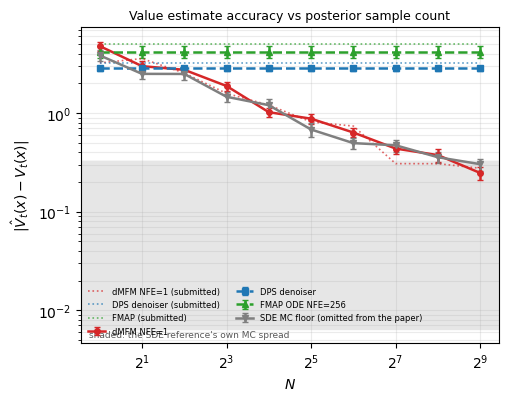

In [5]:
PANEL_A_STYLE = {
    "dmfm":   ("dMFM NFE=1",        "o", "#d62728", "-"),
    "dps":    ("DPS denoiser",      "s", "#1f77b4", "--"),
    "fmap":   ("FMAP ODE NFE=256",  "^", "#2ca02c", "--"),
    "sde_mc": ("SDE MC floor (omitted from the paper)", "v", "#7f7f7f", "-"),
}
OLD_LEFT = {"dMFM NFE=1": "#d62728", "DPS denoiser": "#1f77b4", "FMAP": "#2ca02c"}

def draw_panel_a(ax, df, floor, title, show_old=False):
    for m, (lab, mk, c, ls) in PANEL_A_STYLE.items():
        g = df[df.method == m]
        if len(g):
            ax.errorbar(g.n_samples, g.abs_V_err_mean, yerr=g.abs_V_err_sem, marker=mk, color=c, ls=ls,
                        lw=1.8, ms=4, capsize=2, label=lab)
    if show_old:
        for series, c in OLD_LEFT.items():
            g = old_left[old_left.series == series]
            ax.plot(g.N, g.value_error, color=c, ls=":", lw=1.2, alpha=0.7, label=f"{series} (submitted)")
    if floor:
        lo = floor["selfsplit_abs_diff_mean"]
        ax.axhline(lo, color="0.6", lw=0.8, zorder=0)
        ax.axhspan(lo / 50, lo, color="0.9", zorder=0)
    ax.set_xscale("log", base=2); ax.set_yscale("log")
    ax.set_xlabel("$N$"); ax.set_ylabel(r"$|\hat V_t(x) - V_t(x)|$")
    ax.set_title(title, fontsize=9); ax.grid(alpha=0.25, which="both")

fig, ax = plt.subplots(figsize=(5.4, 4.1))
if pa is not None:
    draw_panel_a(ax, pa, fl, "Value estimate accuracy vs posterior sample count", show_old=True)
    ax.text(0.02, 0.02, "shaded: the SDE reference's own MC spread", transform=ax.transAxes, fontsize=6.5, color="0.35")
    ax.legend(fontsize=6.0, frameon=False, ncol=2)
else:
    ax.text(0.5, 0.5, "panel A pending\n(scripts/dna/fig4_all.sbatch)", ha="center", va="center",
            transform=ax.transAxes, fontsize=9, color="0.4"); ax.set_axis_off()
savefig(fig, "dna_fig4_left_value_error.png")
plt.show()

In [6]:
# submitted (digitized from the PDF) vs rerun, at every N. Same protocol and same reward as the
# original producer, but the split65k models and their dMFM are purged, so MISMATCH is expected:
# this table documents the change, it is not a reproduction test.
# The published panel's own n_conditions is unrecorded; 8 is the shared default of the
# original script and its launcher, so the comparison uses conditions 0-7 only.
pa8 = panel_a("panelA_value_error_first8_conditions.csv")
if pa is not None:
    src = pa8 if pa8 is not None else pa
    print("compared on", "conditions 0-7 (the original protocol's count)" if pa8 is not None
          else "all collected conditions (only 8 were run)")
    got = src.set_index(["method", "n_samples"])["abs_V_err_mean"]
    rows = []
    for series, m in [("dMFM NFE=1", "dmfm"), ("DPS denoiser", "dps"), ("FMAP", "fmap")]:
        for _, r in old_left[old_left.series == series].iterrows():
            rows.append({"item": f"Fig4L {series} N={int(r.N)}", "paper": round(float(r.value_error), 3),
                         "ours": float(got.get((m, int(r.N)), np.nan)), "dec": 2,
                         "note": "digitized from the PDF; rerun on parent-disjoint models"})
    show(cmp(rows))

compared on conditions 0-7 (the original protocol's count)
status counts: {'MISMATCH': 30}


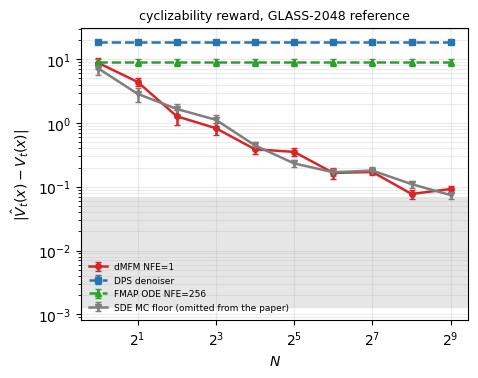

In [7]:
# Robustness: the same protocol with the cyclizability reward of the right panel and a GLASS-2048
# reference instead of the synthetic reward and the teacher-SDE reference.
pa_c0 = panel_a("panelA_value_error_c0_reward.csv")
if pa_c0 is not None:
    fl_c0 = load_json("dna/fig4/summary.json")["panelA_c0_reward"]["reference_floor"]
    fig, ax = plt.subplots(figsize=(5.0, 3.8))
    draw_panel_a(ax, pa_c0, fl_c0, "cyclizability reward, GLASS-2048 reference")
    ax.legend(fontsize=6.5, frameon=False)
    savefig(fig, "dna_fig4_left_robustness.png"); plt.show()
else:
    print("robustness variant (panelA_c0) not collected yet")

---
## Fig 4 (right) — target error vs NFE

In [8]:
if have("panelB_curves.csv"):
    pb = load_csv("dna/fig4/panelB_curves.csv")
    display(pb[["method", "config", "nfe_gen_per_output", "nfe_guide_per_output", "nfe_backward_per_output",
                "mae_mean", "mae_sem", "frac10_mean", "oracle_mae_mean", "n_repeats"]].round(4))
else:
    pb = None
    print("panel B not collected yet -- run scripts/dna/fig4_panelB.sbatch, then scripts/dna/fig4_collect.sh")

,method,config,nfe_gen_per_output,nfe_guide_per_output,nfe_backward_per_output,mae_mean,mae_sem,frac10_mean,oracle_mae_mean,n_repeats
0,beam,"W=1,L=4,K=48",576.0000,8.0,0.0,0.1516,0.0127,0.4367,0.1900,3
1,beam,"W=1,L=4,K=32",768.0000,12.0,0.0,0.0985,0.0034,0.6100,0.1726,3
2,beam,"W=1,L=4,K=24",960.0000,16.0,0.0,0.0695,0.0037,0.7767,0.1387,3
3,beam,"W=1,L=4,K=16",1344.0000,24.0,0.0,0.0585,0.0031,0.8067,0.1465,3
4,beam,"W=1,L=4,K=12",1728.0000,32.0,0.0,0.0441,0.0021,0.9033,0.1347,3
5,beam,"W=1,L=4,K=8",2496.0000,48.0,0.0,0.0296,0.0020,0.9700,0.1331,3
6,beam,"W=1,L=4,K=6",3264.0000,64.0,0.0,0.0208,0.0012,0.9833,0.1269,3
7,beam,"W=1,L=4,K=4",4800.0000,96.0,0.0,0.0143,0.0003,1.0000,0.1185,3
8,best_of_n,N=2,192.0000,2.0,0.0,0.4082,0.0159,0.1033,0.3986,3
9,best_of_n,N=3,288.0000,3.0,0.0,0.3081,0.0100,0.1867,0.3234,3


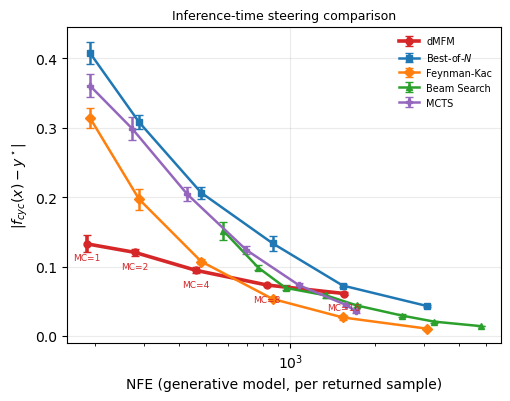

In [9]:
PANEL_B_STYLE = {
    "dmfm":      ("dMFM",        "o", "#d62728", 2.6),
    "best_of_n": ("Best-of-$N$", "s", "#1f77b4", 1.8),
    "fk":        ("Feynman-Kac", "D", "#ff7f0e", 1.8),
    "beam":      ("Beam Search", "^", "#2ca02c", 1.8),
    "mcts":      ("MCTS",        "P", "#9467bd", 1.8),
}
fig, ax = plt.subplots(figsize=(5.6, 4.1))
if pb is not None and len(pb):
    for m, (lab, mk, c, lw) in PANEL_B_STYLE.items():
        g = pb[pb.method == m].sort_values("nfe_gen_per_output")
        if len(g):
            ax.errorbar(g.nfe_gen_per_output, g.mae_mean, yerr=g.mae_sem, marker=mk, color=c,
                        lw=lw, ms=5, capsize=3, label=lab)
    for _, r in pb[pb.method == "dmfm"].iterrows():
        ax.annotate(r.config, (r.nfe_gen_per_output, r.mae_mean), textcoords="offset points",
                    xytext=(0, -12), fontsize=6.5, color="#d62728", ha="center")
    ax.set_xscale("log")
    ax.set_xlabel("NFE (generative model, per returned sample)")
    ax.set_ylabel(r"$|f_{cyc}(x) - y^\star|$")
    ax.set_title("Inference-time steering comparison", fontsize=9)
    ax.grid(alpha=0.25); ax.legend(fontsize=7, frameon=False)
else:
    ax.text(0.5, 0.5, "panel B pending\n(scripts/dna/fig4_panelB.sbatch)", ha="center", va="center",
            transform=ax.transAxes, fontsize=9, color="0.4"); ax.set_axis_off()
savefig(fig, "dna_fig4_right_nfe_benchmark.png")
plt.show()

### Does the dMFM still win at low NFE?

The paper's claim: "dMFM achieves low target error at low NFEs, the regime most relevant
for practical sampling". The table reads every baseline curve at exactly the NFE of each
dMFM point (linear interpolation in log NFE; `NaN` where that NFE lies outside the
baseline's own budget range, e.g. below beam search's minimum of 288).

In [10]:
if pb is not None and len(pb):
    s = load_json("dna/fig4/summary.json")["panelB"]
    cmpdf = pd.DataFrame(s["matched_nfe_comparison"])
    display(cmpdf.round(4))
    for _, row in cmpdf.iterrows():
        others = {k.replace("_mae_at_same_nfe", ""): v for k, v in row.items() if k.endswith("_mae_at_same_nfe") and v == v}
        if others:
            k, v = min(others.items(), key=lambda kv: kv[1])
            verdict = "dMFM best" if row["dmfm_mae"] <= v else f"{k} better"
            print(f"{row['dmfm_config']:>6s} @ {row['nfe']:6.0f} NFE: dMFM {row['dmfm_mae']:.3f} | best baseline {k} {v:.3f} -> {verdict}")
    # lowest NFE any baseline reaches with an error <= dMFM MC=1's
    d1 = pb[(pb.method == "dmfm")].sort_values("nfe_gen_per_output").iloc[0]
    reach = pb[(pb.method != "dmfm") & (pb.mae_mean <= d1.mae_mean)].sort_values("nfe_gen_per_output")
    if len(reach):
        r = reach.iloc[0]
        print(f"\ncheapest baseline point matching dMFM MC=1 ({d1.mae_mean:.3f} at {d1.nfe_gen_per_output:.0f} NFE): "
              f"{r.method} {r.config}, {r.mae_mean:.3f} at {r.nfe_gen_per_output:.0f} NFE "
              f"({r.nfe_gen_per_output / d1.nfe_gen_per_output:.1f}x the NFE)")
    else:
        print(f"\nno baseline point reaches dMFM MC=1's error ({d1.mae_mean:.3f}) within the swept budgets")

,dmfm_config,nfe,dmfm_mae,beam_mae_at_same_nfe,best_of_n_mae_at_same_nfe,fk_mae_at_same_nfe,mcts_mae_at_same_nfe
0,MC=1,187.0,0.1329,NaN,NaN,NaN,NaN
1,MC=2,278.0,0.1206,NaN,0.3168,0.2074,0.2943
2,MC=4,460.0,0.0947,NaN,0.2150,0.1149,0.1924
3,MC=8,824.0,0.0736,0.0894,0.1395,0.0578,0.1042
4,MC=16,1552.0,0.0613,0.0502,0.0724,0.0266,0.0461


  MC=2 @    278 NFE: dMFM 0.121 | best baseline fk 0.207 -> dMFM best
  MC=4 @    460 NFE: dMFM 0.095 | best baseline fk 0.115 -> dMFM best
  MC=8 @    824 NFE: dMFM 0.074 | best baseline fk 0.058 -> fk better
 MC=16 @   1552 NFE: dMFM 0.061 | best baseline fk 0.027 -> fk better

cheapest baseline point matching dMFM MC=1 (0.133 at 187 NFE): fk K=5, 0.107 at 480 NFE (2.6x the NFE)


### Submitted vs rerun

Dotted: what the PDF plotted (digitized). The baseline curves there are the hard-coded CSV
(no producing code, zero error bars), measured on purged models with a purged guide; the
dMFM points come from a lost run (the surviving 2026-05-13 rerun of the same configuration
is shown as open circles). Solid: this rerun.

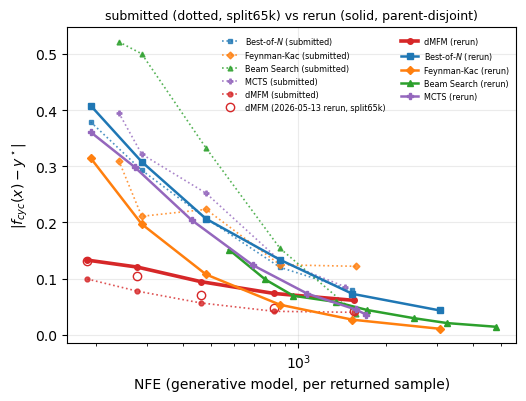

In [11]:
OLD_SERIES = {"Best-of-N": "best_of_n", "Feynman-Kac": "fk", "Beam Search": "beam", "MCTS": "mcts", "dMFM": "dmfm"}
fig, ax = plt.subplots(figsize=(5.8, 4.1))
for series, m in OLD_SERIES.items():
    lab, mk, c, lw = PANEL_B_STYLE[m]
    g = old_right[old_right.series == series].sort_values("nfe")
    ax.plot(g.nfe, g.target_error, marker=mk, color=c, lw=1.2, ms=3.5, ls=":", alpha=0.8, label=f"{lab} (submitted)")
g = old_rerun[old_rerun.method == "dMFM_guided"].sort_values("gen_nfe_per_output")
ax.plot(g.gen_nfe_per_output, g.mae_mean, "o", mfc="none", color="#d62728", ms=6, label="dMFM (2026-05-13 rerun, split65k)")
if pb is not None and len(pb):
    for m, (lab, mk, c, lw) in PANEL_B_STYLE.items():
        g = pb[pb.method == m].sort_values("nfe_gen_per_output")
        if len(g):
            ax.plot(g.nfe_gen_per_output, g.mae_mean, marker=mk, color=c, lw=lw, ms=4, label=f"{lab} (rerun)")
ax.set_xscale("log"); ax.set_xlabel("NFE (generative model, per returned sample)")
ax.set_ylabel(r"$|f_{cyc}(x) - y^\star|$")
ax.set_title("submitted (dotted, split65k) vs rerun (solid, parent-disjoint)", fontsize=9)
ax.grid(alpha=0.25); ax.legend(fontsize=5.8, frameon=False, ncol=2)
savefig(fig, "dna_fig4_right_submitted_vs_rerun.png")
plt.show()

In [12]:
# per-point old -> new for the dMFM curve (MISMATCH expected: different models and guide)
if pb is not None and len(pb):
    new = pb[pb.method == "dmfm"].set_index("config")
    rows = []
    for _, r in old_right[old_right.series == "dMFM"].iterrows():
        mc = 2 ** int(r.point)
        key = f"MC={mc}"
        rows.append({"item": f"Fig4R dMFM {key} |f-y*| (NFE {int(r.nfe)})", "paper": round(float(r.target_error), 3),
                     "ours": float(new.loc[key, "mae_mean"]) if key in new.index else np.nan, "dec": 2,
                     "note": f"new NFE {new.loc[key, 'nfe_gen_per_output']:.0f}" if key in new.index else "pending"})
    show(cmp(rows))

status counts: {'MISMATCH': 5}


### Caveats to carry into the caption and text

1. The NFE axis counts forward passes of a generative network and assumes no parallel
   execution. It is **not** wall-clock: the dMFM additionally makes one backward pass
   through student and guide per guided step (`nfe_backward_per_output` = 91), which none
   of the search baselines needs, while best-of-$N$, FK and beam search parallelise across
   candidates and the dMFM's sequential guidance does not.
2. Every method, the dMFM included, steers against the *same* guide that defines the
   reported error; the independent-oracle column (`oracle_mae_mean`) gives each method's
   error against a regressor it never saw.
3. The left panel's reference $V_t$ is the original's teacher-SDE estimate (512 samples,
   1,024 steps), itself finite-sample; the `sde_mc` series measures its own error and is
   the floor below which no curve can be resolved. The submitted panel omits that series.
4. Search baselines branch through the SDE form of the same base model (same marginals,
   measured above); best-of-$N$ and the dMFM use the deterministic sampler.

---
## RERUN = True — small-n version on one GPU

One budget point per method with $n = 8$ outputs, plus a 2-state panel-A shard, into
`outputs/dna/fig4_nb/` (a few minutes on one GPU). It does **not** touch
`results/dna/fig4/`; the full-size runs go through the Slurm wrappers.

In [13]:
if RERUN:
    import subprocess, sys
    out = REPO / "outputs" / "dna" / "fig4_nb"
    for idx in [0, 5, 11, 17, 25]:          # dMFM MC=1, best-of-2, FK K=2, beam K=48, MCTS I=2
        subprocess.run([sys.executable, "-m", "dmfm.benchmarks.run_steering", "--plan", "sweep",
                        "--index", str(idx), "--repeat", "0", "--n-outputs", "8",
                        "--out-dir", str(out / "panelB" / "sweep")], check=True)
    subprocess.run([sys.executable, "-m", "dmfm.benchmarks.value_error", "--out", str(out / "panelA" / "nb.json"),
                    "--cond-start", "0", "--cond-end", "2", "--n-conditions", "2",
                    "--n-list", "1", "2", "4", "8", "--sde-ref-n", "64", "--sde-steps", "128",
                    "--fmap-nfe", "32"], check=True)
    subprocess.run([sys.executable, "-m", "dmfm.benchmarks.collect", "--panelA-dir", str(out / "panelA"),
                    "--panelA-c0-dir", str(out / "none"), "--panelB-dir", str(out / "panelB" / "sweep"),
                    "--pilot-dir", str(out / "panelB" / "pilot"), "--out", str(out / "results")], check=True)
    display(pd.read_csv(out / "results" / "panelB_curves.csv"))
    display(pd.read_csv(out / "results" / "panelA_value_error.csv")
            .pivot_table(index="n_samples", columns="method", values="abs_V_err_mean"))
else:
    print("RERUN = False: everything above was rebuilt from results/dna/fig4/ on CPU.")

RERUN = False: everything above was rebuilt from results/dna/fig4/ on CPU.
